In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:

df = pd.read_csv("Dataset .csv")
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [7]:
print(df.columns.tolist())

['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes']


Rating Text Distribution:
Rating text
Average      3737
Not rated    2148
Good         2100
Very Good    1079
Excellent     301
Poor          186
Name: count, dtype: int64

Average Rating by Rating Text:
Rating text
Average      3.051619
Excellent    4.659801
Good         3.683429
Not rated    0.000000
Poor         2.297849
Very Good    4.168119
Name: Aggregate rating, dtype: float64


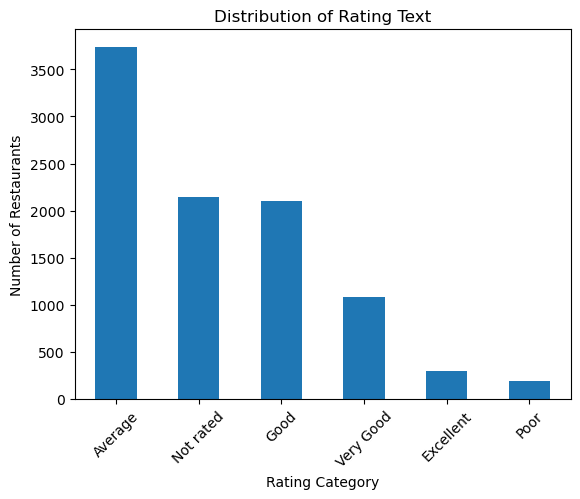

In [8]:
# level 3
# Level 3 - Task 1 (Alternative using Rating Text)

import matplotlib.pyplot as plt

# Rating Text Distribution
rating_text = df['Rating text'].value_counts()

print("Rating Text Distribution:")
print(rating_text)

# Average Rating by Rating Text
avg_rating = df.groupby('Rating text')['Aggregate rating'].mean()

print("\nAverage Rating by Rating Text:")
print(avg_rating)

# Bar Chart
rating_text.plot(kind='bar')
plt.title('Distribution of Rating Text')
plt.xlabel('Rating Category')
plt.ylabel('Number of Restaurants')
plt.xticks(rotation=45)
plt.show()

Restaurant with Highest Votes:
Restaurant Name      Toit
Votes               10934
Aggregate rating      4.8
Name: 728, dtype: object

Restaurant with Lowest Votes:
Restaurant Name     Cantinho da Gula
Votes                              0
Aggregate rating                 0.0
Name: 69, dtype: object

Correlation between Votes and Rating:
0.3136905841954107


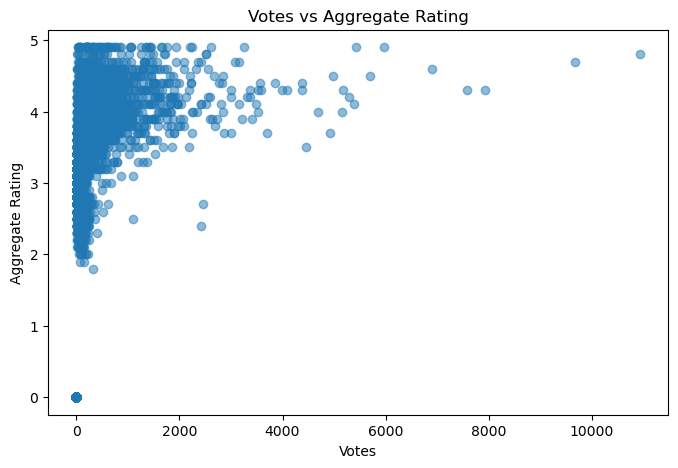

In [4]:
#level 3 
# Task 2: Votes Analysis

highest_votes = df.loc[df['Votes'].idxmax()]
lowest_votes = df.loc[df['Votes'].idxmin()]

print("Restaurant with Highest Votes:")
print(highest_votes[['Restaurant Name', 'Votes', 'Aggregate rating']])

print("\nRestaurant with Lowest Votes:")
print(lowest_votes[['Restaurant Name', 'Votes', 'Aggregate rating']])

# Correlation
correlation = df['Votes'].corr(df['Aggregate rating'])

print("\nCorrelation between Votes and Rating:")
print(correlation)

# Plot
plt.figure(figsize=(8,5))
plt.scatter(df['Votes'], df['Aggregate rating'], alpha=0.5)
plt.title('Votes vs Aggregate Rating')
plt.xlabel('Votes')
plt.ylabel('Aggregate Rating')
plt.show()

Price Range vs Online Delivery
Has Online delivery    No   Yes
Price range                    
1                    3743   701
2                    1827  1286
3                     997   411
4                     533    53

Online Delivery Percentage
Has Online delivery         No        Yes
Price range                              
1                    84.225923  15.774077
2                    58.689367  41.310633
3                    70.809659  29.190341
4                    90.955631   9.044369


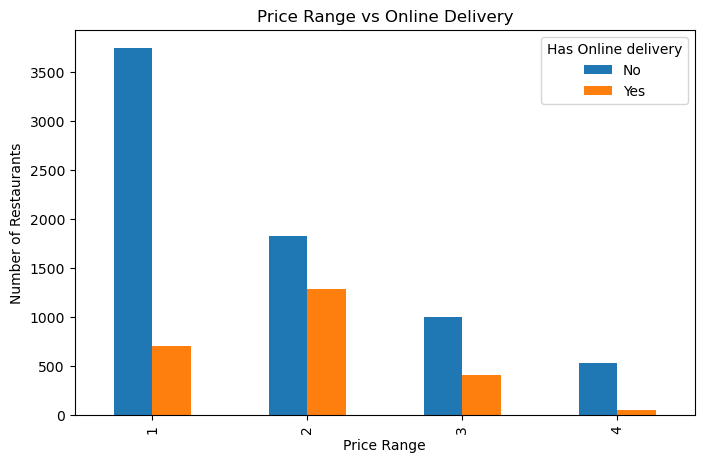


Price Range vs Table Booking
Has Table booking    No  Yes
Price range                 
1                  4443    1
2                  2874  239
3                   764  644
4                   312  274

Table Booking Percentage
Has Table booking         No        Yes
Price range                            
1                  99.977498   0.022502
2                  92.322518   7.677482
3                  54.261364  45.738636
4                  53.242321  46.757679


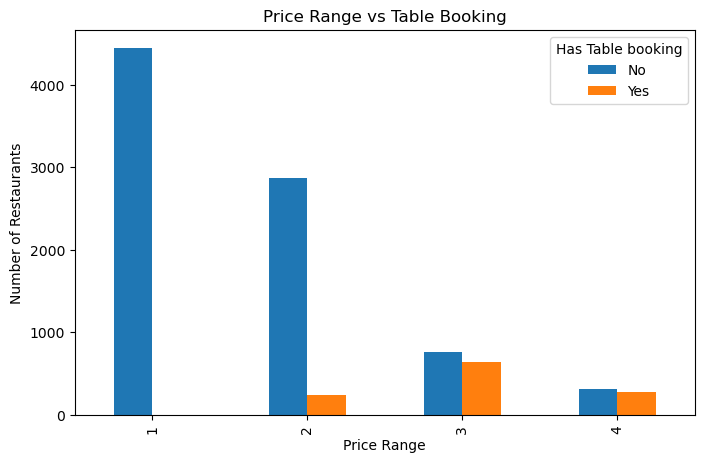

In [5]:
# level 3 
# task 3 Price Range vs Online Delivery and table booking
online_delivery = pd.crosstab(
    df['Price range'],
    df['Has Online delivery']
)

print("Price Range vs Online Delivery")
print(online_delivery)

print("\nOnline Delivery Percentage")
print(
    pd.crosstab(
        df['Price range'],
        df['Has Online delivery'],
        normalize='index'
    ) * 100
)

online_delivery.plot(kind='bar', figsize=(8,5))
plt.title('Price Range vs Online Delivery')
plt.xlabel('Price Range')
plt.ylabel('Number of Restaurants')
plt.show()


# Price Range vs Table Booking
table_booking = pd.crosstab(
    df['Price range'],
    df['Has Table booking']
)

print("\nPrice Range vs Table Booking")
print(table_booking)

print("\nTable Booking Percentage")
print(
    pd.crosstab(
        df['Price range'],
        df['Has Table booking'],
        normalize='index'
    ) * 100
)

table_booking.plot(kind='bar', figsize=(8,5))
plt.title('Price Range vs Table Booking')
plt.xlabel('Price Range')
plt.ylabel('Number of Restaurants')
plt.show()